Model: "functional"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_layer (InputLayer)        │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block1_conv1 (Conv2D)           │ (None, 224, 224, 64)   │         1,792 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block1_conv2 (Conv2D)           │ (None, 224, 224, 64)   │        36,928 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 38,720 (151.25 KB)

 Trainable params: 38,720 (151.25 KB)

 Non-trainable params: 0 (0.00 B)

Feature maps: (1, 224, 224, 64)


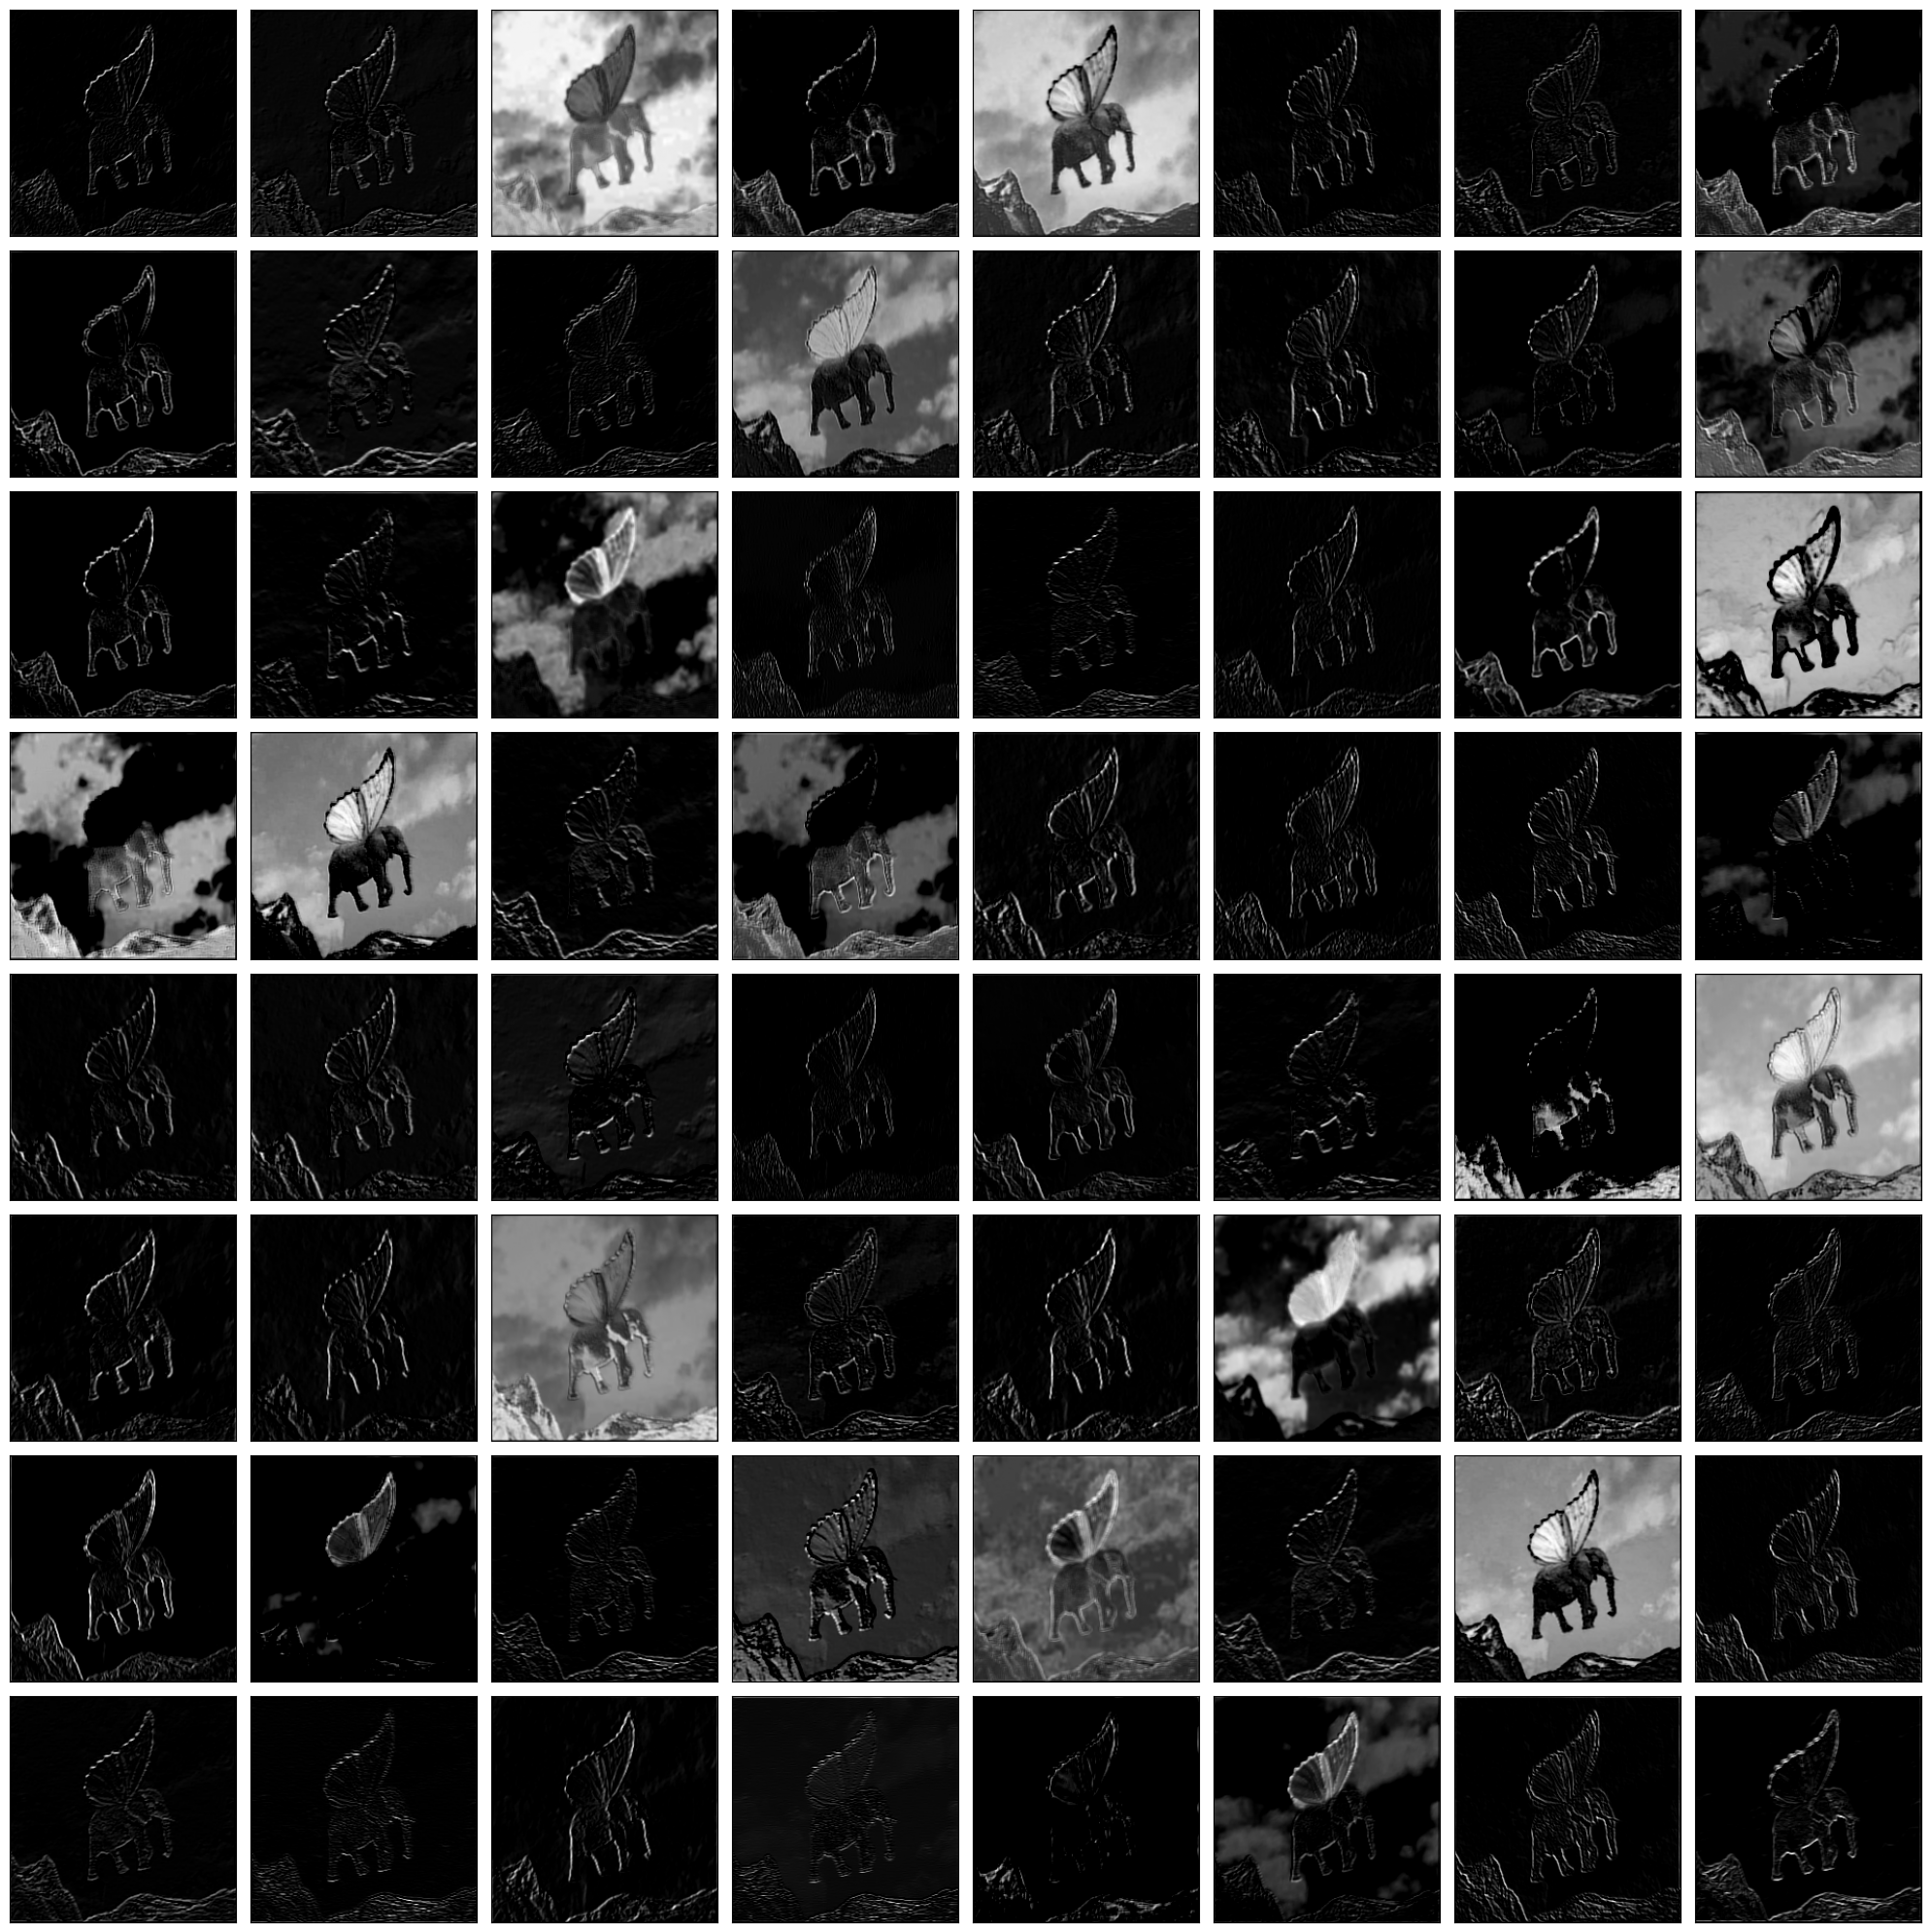

In [1]:
# Exercise 4.17
# Visualize feature maps from the second convolutional layer

from keras.applications.vgg19 import VGG19, preprocess_input
from keras.preprocessing.image import load_img, img_to_array
from keras.models import Model
import matplotlib.pyplot as plt
from numpy import expand_dims


# ============================================================
# 1. FUNCTION TO PLOT FEATURE MAPS
# ============================================================

def plot_feature_maps(feature_maps):
    col = 8
    row = int(feature_maps.shape[3] / col)
    ix = 1

    plt.figure(figsize=(20, 20))

    for _ in range(row):
        for _ in range(col):
            ax = plt.subplot(row, col, ix)
            ax.set_xticks([])
            ax.set_yticks([])

            plt.imshow(
                feature_maps[0, :, :, ix - 1],
                cmap='gray'
            )

            ix += 1

    plt.tight_layout()
    plt.show()


# ============================================================
# 2. LOAD VGG19 MODEL
# ============================================================

model = VGG19()


# ============================================================
# 3. SELECT LAYER TO VISUALIZE
# ============================================================

n = 2


# ============================================================
# 4. CREATE MODEL WITH SELECTED LAYER AS OUTPUT
# ============================================================

feature_model = Model(
    inputs=model.inputs,
    outputs=model.layers[n].output
)

feature_model.summary()


# ============================================================
# 5. LOAD IMAGE
# ============================================================

img = load_img(
    'Elephant.jpg',
    target_size=(224, 224)
)


# ============================================================
# 6. CONVERT IMAGE TO ARRAY
# ============================================================

img = img_to_array(img)


# ============================================================
# 7. EXPAND DIMENSIONS
# ============================================================

img = expand_dims(
    img,
    axis=0
)


# ============================================================
# 8. PREPROCESS IMAGE
# ============================================================

img = preprocess_input(img)


# ============================================================
# 9. GET FEATURE MAPS
# ============================================================

feature_maps = feature_model.predict(
    img,
    verbose=0
)

print("Feature maps:", feature_maps.shape)


# ============================================================
# 10. DISPLAY FEATURE MAPS
# ============================================================

plot_feature_maps(feature_maps)